> **Language & Quick Links**: [🇰🇷 Korean (`notebooks/ko/stage4_agent_and_mcp_execution_ko.ipynb`)](../ko/stage4_agent_and_mcp_execution_ko.ipynb) · **🇺🇸 English (Current Folder: `notebooks/en/`)** ｜ [Methodology Guide](../../methodology/en/04_stage4_agent_and_mcp_en.md) ｜ [Notebook Index (README)](../README.md) ｜ [Open Live Studio Tab](https://agentic-ontology-starter-lwrlf7yogq-du.a.run.app/?tab=stage4)
>
> **Lifecycle Navigation**: [0. End-to-End Overview](./stage0_overview_walkthrough_en.ipynb) → [Stage 1 · Prepare & Analyze](./stage1_asset_and_cq_en.ipynb) → [Stage 2 · Parse & Integrate](./stage2_wiki_and_semantic_graph_en.ipynb) → [Stage 3 · Build Property Graph](./stage3_property_graph_bigquery_spanner_en.ipynb) → **[▶ Stage 4 · Build Agent & Answer](./stage4_agent_and_mcp_execution_en.ipynb)** → [Stage 5 · Verify & Evaluate](./stage5_lineage_and_evaluation_en.ipynb)

---

# Stage 4. [Build Agent & Answer] 8-Tool Modular MCP Server, Slot Validation & 2-Pass AI FDE Agent Execution
## Step 4.1 8 MCP Tools & 2-Pass Agent Architecture Setup · Step 4.2 Deterministic Penalty Simulation & Guardrailed Answering

Stage 4 implements **Phase 6 (Agent & MCP Setup)** and **Phase 7 (Grounded Answering)**. To prevent LLM math errors or entity hallucinations, we combine **(1) Live BigQuery Catalog Slot Validation (`resolve_params`)**, **(2) the 8-Tool Modular MCP Server (`DomainMcpServer`) executing deterministic SQL and parameterized ISO GQL across both `engine="bigquery"` (default) and `engine="spanner"`**, and **(3) the 4-Step, 2-Pass Gemini (`gemini-3.8-flash`) Reasoning Engine (`AiFdeAgentEngine`)**, verifying both `GROUNDED` answers and boundary guardrails (`INSUFFICIENT_PARAMETERS`, `MATCH_NOT_FOUND`).

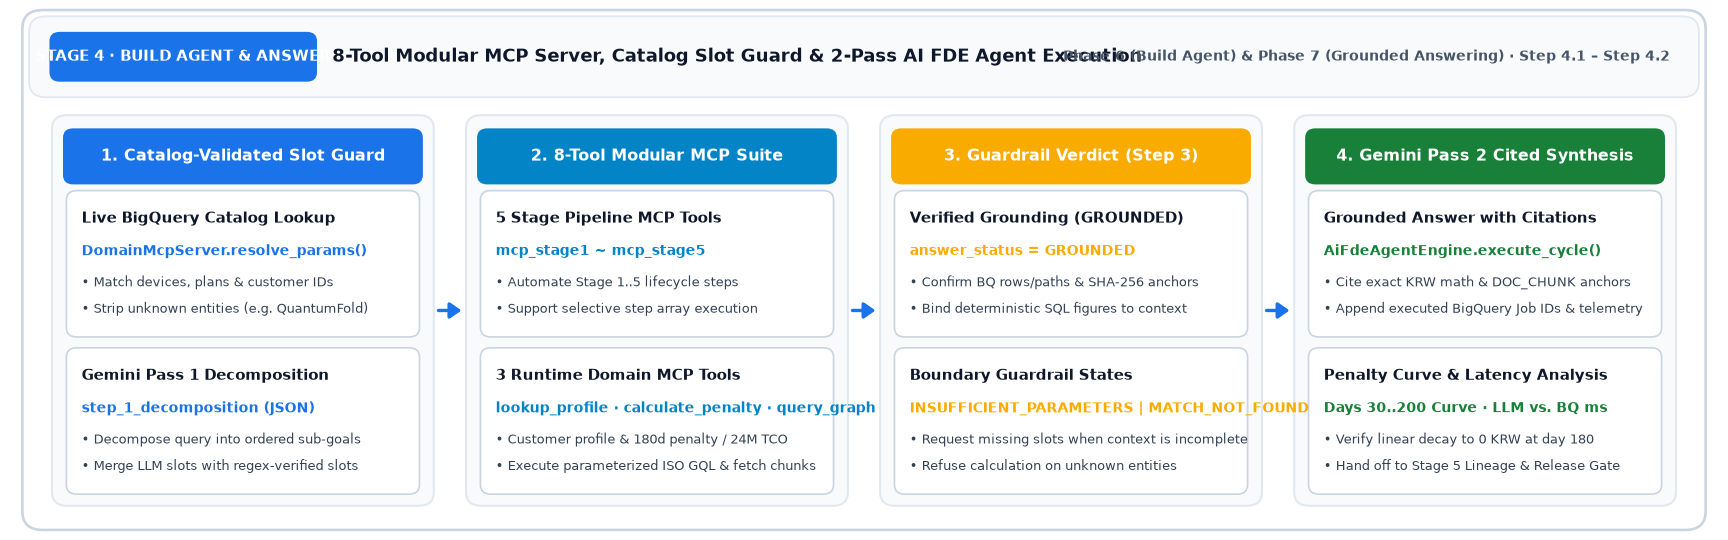


In [1]:
%load_ext bigframes
import sys
from pathlib import Path
for _p in (Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent):
    if (_p / "nb_helpers.py").exists() and str(_p) not in sys.path:
        sys.path.insert(0, str(_p))
import pandas as pd
import nb_helpers as H
from src.agent.mcp_server import DomainMcpServer
from src.agent.reasoning_engine import AiFdeAgentEngine
H.setup("en")
server = DomainMcpServer()
agent = AiFdeAgentEngine()


### 1. [Phase 6a: Agent & MCP Architecture Setup] 2-Pass Orchestration Blueprint, 8-Tool MCP Catalog & `mcp_stage4_agent_orchestration`


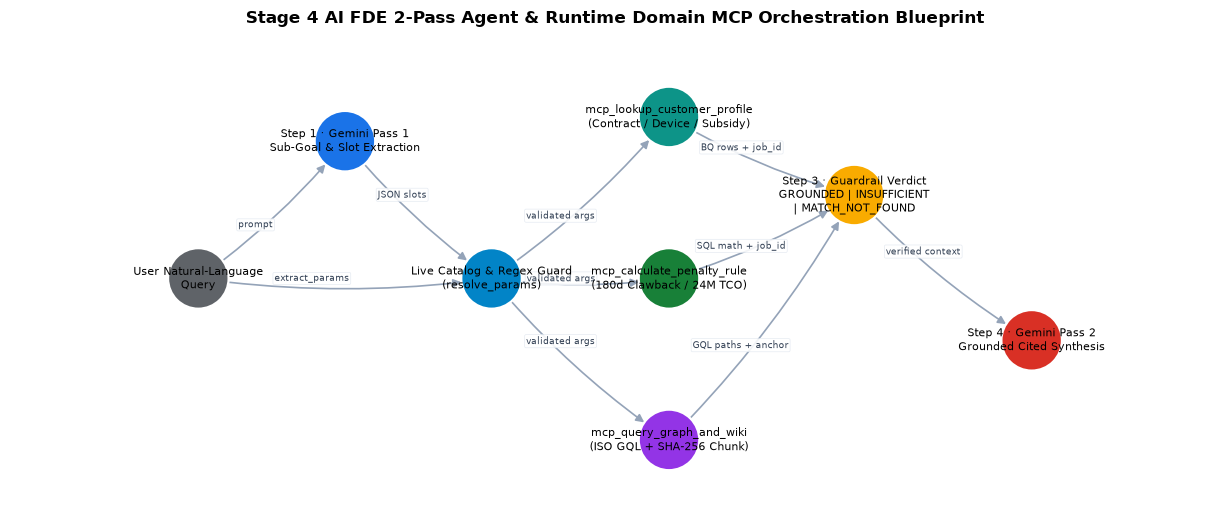

,name,stage,category,steps,spec_origin,description_en
0,mcp_stage1_asset_discovery,STAGE 1,stage_pipeline,"[profile_tables, scan_guides, prune_noise, tag_pii_governance]",GCP_NATIVE,Stage 1 live BigQuery / Cloud Spanner table profiling and customer ID de-identificatio...
1,mcp_stage2_wiki_and_semantic,STAGE 2,stage_pipeline,"[compile_3layer_wiki, extract_hash_anchors, bind_semantic_bridges]",CUSTOM_EXTENSION,Stage 2 GCS wiki object listing and BigQuery / Spanner chunk/rule anchor lookup
2,mcp_stage3_property_graph,STAGE 3,stage_pipeline,"[promote_dw_nodes, synthesize_graph_ddl, verify_gql_templates]",GCP_NATIVE,Stage 3 node-table duplicate-key check and Property Graph (BigQuery / Spanner) GQL pat...
3,mcp_stage4_agent_orchestration,STAGE 4,stage_pipeline,"[decompose_subgoals, dispatch_domain_mcps, verify_grounding_anchors]",CUSTOM_EXTENSION,Stage 4 domain rules and grounding chunks used by the agent (BigQuery / Spanner)
4,mcp_stage5_lineage_and_eval,STAGE 5,stage_pipeline,"[build_4tier_lineage, run_golden_cq_suite, diagnose_boundary_failures]",CUSTOM_EXTENSION,Stage 5 contract→device/plan/subsidy→rule→chunk lineage join and latest validation sum...
5,mcp_lookup_customer_profile,RUNTIME,runtime_domain,"[lookup_contract, lookup_device_price, lookup_subsidy_policy]",CUSTOM_EXTENSION,"Customer contract, device price and subsidy lookup on BigQuery or Cloud Spanner"
6,mcp_calculate_penalty_rule,RUNTIME,runtime_domain,"[check_exemptions, compute_180d_prorated_clawback, compare_24m_tco]",CUSTOM_EXTENSION,"180-day prorated penalty, exemption and 24-month TCO computed in BigQuery or Cloud Spa..."
7,mcp_query_graph_and_wiki,RUNTIME,runtime_domain,"[traverse_property_graph, fetch_okf_hash_anchor, verify_dw_schema]",GCP_NATIVE,Property Graph GRAPH_TABLE multi-hop traversal (BigQuery / Spanner) and grounding chun...


**`mcp_stage4_agent_orchestration`** · engine `bigquery` · status `SUCCESS` · steps `decompose_subgoals, dispatch_domain_mcps, verify_grounding_anchors` · jobs 1 (484.5 ms)

Retrieved 4 codified domain rules and grounding chunk anchors (bigquery)

- `job_cDjnFcyTda-oQdG39thQBd6OO51H`

,rule_id,rule_name,rule_category,condition_expr,formula_expr,source_chunk_id,anchor
0,RULE_SIX_PLAN_180D,"180-Day Baseline (45,000 KRW) Mandatory Retention & Prorated Penalty Rule",PENALTY_180D,elapsed_days < 180 AND target_plan_monthly_fee < 45000,penalty = ROUND((initial_base_subsidy - lower_tier_base_subsidy) * (180 - elapsed_days...,DOC_CHUNK_003,anchor_47971ec8e4d8
1,RULE_SUBSIDY_CAP,Public Subsidy & Retail Additional Subsidy Cap (15%) Rule,SUBSIDY_CAP,contract_type == 'PUBLIC_SUBSIDY',total_subsidy = base_subsidy_krw + additional_subsidy_cap_krw; net_principal = factory...,DOC_CHUNK_001,anchor_a52e1a72869f
2,RULE_TCO_24M,24-Month Public Subsidy vs. 25% Selective Contract TCO Comparison Rule,TCO_24M,commitment_months == 24,subsidy_24m_tco = (factory_price_krw - total_subsidy) + (monthly_fee_krw * 24); select...,DOC_CHUNK_005,anchor_4fbaf9c5cba8
3,RULE_WELFARE_EXEMPT,Senior/Welfare Plan Transition & Military Suspension Penalty Exemption Rule,WELFARE_EXEMPT,"welfare_status IN ('SENIOR_EXEMPT', 'MILITARY_PAUSE_ELIGIBLE')",penalty = 0 (SENIOR_EXEMPT) OR pause_commitment_counter (MILITARY_PAUSE_ELIGIBLE),DOC_CHUNK_004,anchor_269d9c42e05c


In [2]:
H.draw_agent_architecture()
H.show(pd.DataFrame(server.get_tool_catalog()), ["name", "stage", "category", "steps", "spec_origin", "description" if H.LANG == "ko" else "description_en"])
res_s4 = server.execute_tool("mcp_stage4_agent_orchestration", {"steps": ["decompose_subgoals", "dispatch_domain_mcps", "verify_grounding_anchors"]})
H.show_tool(res_s4, "active_rules")


### 2. [Phase 6b: Catalog-Validated Slot Resolution (`resolve_params`)] Extracting Parameters & Stripping Unregistered Entities


In [3]:
sample_queries = [
    "If customer CUST_DEMO_001 downgrades to 5G Light (37,000 KRW) on day 120, what is the penalty?",
    "When activating the AlphaPhone 16 Pro 256GB on the 5G Signature 115 plan, what are the subsidy and net price?",
    "What is the penalty if customer CUST_NOT_EXIST_999 switches to a 99,000 KRW plan on a QuantumFold 99 device?",
    "I just activated my line—what is the penalty if I downgrade to the 37,000 KRW plan?",
]
slot_rows = []
for q in sample_queries:
    resolved = server.resolve_params({"query": q})
    slot_rows.append({"query": q, **{k: v for k, v in resolved.items()}})
H.show(pd.DataFrame(slot_rows))


,query,customer_id,device_name,storage_gb,plan_name,monthly_fee_krw,target_plan_name,target_monthly_fee_krw,elapsed_days
0,"If customer CUST_DEMO_001 downgrades to 5G Light (37,000 KRW) on day 120, what is the ...",CUST_DEMO_001,None,NaN,5G Light (Below Baseline),NaN,None,37000.0,120.0
1,"When activating the AlphaPhone 16 Pro 256GB on the 5G Signature 115 plan, what are the...",NaN,None,256.0,NaN,NaN,None,NaN,NaN
2,"What is the penalty if customer CUST_NOT_EXIST_999 switches to a 99,000 KRW plan on a ...",NaN,None,NaN,NaN,99000.0,None,NaN,NaN
3,"I just activated my line—what is the penalty if I downgrade to the 37,000 KRW plan?",NaN,None,NaN,NaN,37000.0,None,NaN,NaN


### 3. [Phase 6c: Direct Execution of 3 Runtime Domain MCP Tools] Customer Profile, Penalty/24M TCO Math, Graph Traversal (`executed_gql` + Bound Variables) & 180-Day Penalty Curve


**`mcp_lookup_customer_profile`** · engine `bigquery` · status `SUCCESS` · steps `lookup_contract, lookup_device_price, lookup_subsidy_policy` · jobs 1 (485.9 ms)

**1) Bound GQL Variables & Parameters**

| `Variable / Slot` | `Bound Value` | Type / Binding Target |
|:---|:---|:---|
| `customer_id` | `CUST_DEMO_001` | Validated catalog slot via DomainMcpServer.resolve_params() |

- `job_vFP-owPJDcf7_0iq8NYvJQ-Xor4B`

,customer_id,device_name,plan_name,monthly_fee_krw,factory_price_krw,total_subsidy_krw,net_installment_principal_krw,grounded_chunk_id
0,CUST_DEMO_001,Galaxy S26 Ultra 256GB,5G Premier Essential,85000,1698400,517500,1180900,DOC_CHUNK_001


**`mcp_calculate_penalty_rule`** · engine `bigquery` · status `SUCCESS` · steps `check_exemptions, compute_180d_prorated_clawback, compare_24m_tco` · jobs 2 (1,028.7 ms)

**1) Bound GQL Variables & Parameters**

| `Variable / Slot` | `Bound Value` | Type / Binding Target |
|:---|:---|:---|
| `customer_id` | `CUST_DEMO_001` | Validated catalog slot via DomainMcpServer.resolve_params() |
| `target_monthly_fee_krw` | `37000` | Validated catalog slot via DomainMcpServer.resolve_params() |
| `elapsed_days` | `120` | Validated catalog slot via DomainMcpServer.resolve_params() |

- `job_N_kRR5EIvz2nxT9j-sEmXiFEnvcQ`
- `job_D90LVyEkFG3PborcXlWMJZgpRPfV`

,customer_id,plan_name,target_plan_name,elapsed_days,penalty_status,penalty_krw,public_subsidy_24m_tco_krw,selective_24m_tco_krw,tco_recommendation,grounded_chunk_id
0,CUST_DEMO_001,5G Premier Essential,5G Light (Below Baseline),120,PRORATED_PENALTY,100000,3220900,3228400,PUBLIC_SUBSIDY,DOC_CHUNK_003


**`mcp_query_graph_and_wiki`** · engine `bigquery` · status `SUCCESS` · steps `traverse_property_graph, fetch_okf_hash_anchor, verify_dw_schema` · jobs 1 (506.5 ms)

**1) Bound GQL Variables & Parameters**

| `Variable / Slot` | `Bound Value` | Type / Binding Target |
|:---|:---|:---|
| `customer_id` | `CUST_DEMO_001` | Validated catalog slot via DomainMcpServer.resolve_params() |

**Executed GRAPH_TABLE / ISO GQL Statement**
```sql
SELECT g.*, ch.section_title, ch.content_sha256 AS anchor, ch.content AS chunk_text
FROM GRAPH_TABLE(`seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
  MATCH (c:CustomerContractNode)-[:USES_DEVICE]->(d:DeviceNode), (c)-[:SUBSCRIBES_PLAN]->(p:PlanNode)<-[ap:APPLIES_TO_PLAN]-(r:DomainRuleNode)
  COLUMNS (c.customer_id AS customer_id, c.contract_id AS contract_id, c.welfare_status AS welfare_status, c.elapsed_days AS elapsed_days, d.device_name AS device_name, d.factory_price_krw AS factory_price_krw,
           p.plan_name AS plan_name, p.monthly_fee_krw AS monthly_fee_krw,
           r.rule_id AS rule_id, r.rule_name AS rule_name,
           ap.relation_label_ko AS relation_label_ko, ap.source_chunk_id AS source_chunk_id)) g
LEFT JOIN `seanjung-poc.starter_ontology_dw.tb_doc_chunks` ch ON ch.chunk_id = g.source_chunk_id
WHERE g.customer_id = 'CUST_DEMO_001'
ORDER BY g.device_name, g.monthly_fee_krw DESC, g.rule_id
```

- `job_thtvtU2TMLyZ4KEnOHrzq9RrnSAb`

,customer_id,device_name,plan_name,rule_id,relation_label_ko,source_chunk_id,anchor
0,CUST_DEMO_001,Galaxy S26 Ultra 256GB,5G Premier Essential,RULE_SIX_PLAN_180D,180-day baseline retention duty applies,DOC_CHUNK_002,anchor_3003b683cea0
1,CUST_DEMO_001,Galaxy S26 Ultra 256GB,5G Premier Essential,RULE_TCO_24M,24-month public subsidy vs. selective contract TCO applies,DOC_CHUNK_005,anchor_4fbaf9c5cba8


,elapsed_days,penalty_krw,penalty_status,applied_rule_id,public_24m_tco_krw,selective_24m_tco_krw,bq_job_id
0,30,250000,PRORATED_PENALTY,RULE_SIX_PLAN_180D,3220900,3228400,job_U1e2yaXjlcYfgwUaZf8IXuuSifJx
1,60,200000,PRORATED_PENALTY,RULE_SIX_PLAN_180D,3220900,3228400,job_i3zMw6a5Dxc9ts0IJiX5IlQafy45
2,90,150000,PRORATED_PENALTY,RULE_SIX_PLAN_180D,3220900,3228400,job_bkY3eSc2v0gbK_VG8Sy3z-csg4wl
3,120,100000,PRORATED_PENALTY,RULE_SIX_PLAN_180D,3220900,3228400,job_aiXrdemYd_ARDbfFXzfNkz_DINey
4,150,50000,PRORATED_PENALTY,RULE_SIX_PLAN_180D,3220900,3228400,job_Oy35QL3HfmeaUq47nilPzDT4UAZ4
5,179,1667,PRORATED_PENALTY,RULE_SIX_PLAN_180D,3220900,3228400,job__doYmWHms227vftrJkAwGA7BSb5N
6,180,0,EXEMPT_RETENTION_COMPLETED,RULE_SIX_PLAN_180D,3220900,3228400,job_scZir2nAaoWmjDmgg9ZnKjdItk37
7,200,0,EXEMPT_RETENTION_COMPLETED,RULE_SIX_PLAN_180D,3220900,3228400,job_bvm9C0FeZX9Mo2vdMkY4LuiRE2o8


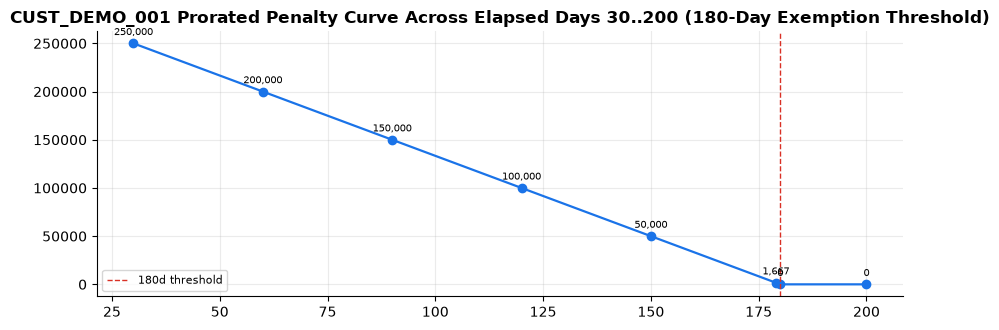

In [4]:
r_prof = server.execute_tool("mcp_lookup_customer_profile", {"customer_id": "CUST_DEMO_001"})
H.show_tool(r_prof, "matched_rows", ["customer_id", "device_name", "plan_name", "monthly_fee_krw", "factory_price_krw", "total_subsidy_krw", "net_installment_principal_krw", "grounded_chunk_id"])

r_pen = server.execute_tool("mcp_calculate_penalty_rule", {"customer_id": "CUST_DEMO_001", "target_monthly_fee_krw": 37000, "elapsed_days": 120})
H.show_tool(r_pen, "calculations", ["customer_id", "plan_name", "target_plan_name", "elapsed_days", "penalty_status", "penalty_krw", "public_subsidy_24m_tco_krw", "selective_24m_tco_krw", "tco_recommendation", "grounded_chunk_id"])

r_gql = server.execute_tool("mcp_query_graph_and_wiki", {"customer_id": "CUST_DEMO_001"})
H.show_tool(r_gql, "matched_graph_paths", ["customer_id", "device_name", "plan_name", "rule_id", "relation_label_ko", "source_chunk_id", "anchor"])

df_curve = H.penalty_curve(server, "CUST_DEMO_001", 37000, [30, 60, 90, 120, 150, 179, 180, 200])
H.show(df_curve)
H.line(df_curve, "elapsed_days", "penalty_krw",
       "CUST_DEMO_001 Prorated Penalty Curve Across Elapsed Days 30..200 (180-Day Exemption Threshold)",
       vline=180, vline_label="180d threshold")


### 4. [Phase 6d: Dual-Engine Runtime MCP Execution (`engine="bigquery"` vs. `engine="spanner"`)] Cloud Spanner Graph Execution Parity & Latency Comparison


**`mcp_query_graph_and_wiki`** · engine `spanner` · status `SUCCESS` · steps `traverse_property_graph, fetch_okf_hash_anchor, verify_dw_schema` · jobs 1 (166.5 ms)

**1) Bound GQL Variables & Parameters**

| `Variable / Slot` | `Bound Value` | Type / Binding Target |
|:---|:---|:---|
| `customer_id` | `CUST_DEMO_001` | Validated catalog slot via DomainMcpServer.resolve_params() |

**Executed GRAPH_TABLE / ISO GQL Statement**
```sql
SELECT g.*, ch.section_title, ch.content_sha256 AS anchor, ch.content AS chunk_text
FROM GRAPH_TABLE(`STARTER_ONTOLOGY_GRAPH`
  MATCH (c:CustomerContractNode)-[:USES_DEVICE]->(d:DeviceNode), (c)-[:SUBSCRIBES_PLAN]->(p:PlanNode)<-[ap:APPLIES_TO_PLAN]-(r:DomainRuleNode)
  COLUMNS (c.customer_id AS customer_id, c.contract_id AS contract_id, c.welfare_status AS welfare_status, c.elapsed_days AS elapsed_days, d.device_name AS device_name, d.factory_price_krw AS factory_price_krw,
           p.plan_name AS plan_name, p.monthly_fee_krw AS monthly_fee_krw,
           r.rule_id AS rule_id, r.rule_name AS rule_name,
           ap.relation_label_ko AS relation_label_ko, ap.source_chunk_id AS source_chunk_id)) g
LEFT JOIN `tb_doc_chunks` ch ON ch.chunk_id = g.source_chunk_id
WHERE g.customer_id = 'CUST_DEMO_001'
ORDER BY g.device_name, g.monthly_fee_krw DESC, g.rule_id
```

- `spanner:starter-spanner/starter_ontology_db@1790745420459`

,customer_id,device_name,plan_name,rule_id,relation_label_ko,source_chunk_id,anchor
0,CUST_DEMO_001,Galaxy S26 Ultra 256GB,5G Premier Essential,RULE_SIX_PLAN_180D,180-day baseline retention duty applies,DOC_CHUNK_002,anchor_3003b683cea0
1,CUST_DEMO_001,Galaxy S26 Ultra 256GB,5G Premier Essential,RULE_TCO_24M,24-month public subsidy vs. selective contract TCO applies,DOC_CHUNK_005,anchor_4fbaf9c5cba8


,mcp_tool,bigquery_status,spanner_status,bigquery_ms,spanner_ms,bq_rows,spanner_rows,result_parity
0,mcp_lookup_customer_profile,SUCCESS,SUCCESS,459.86,1244.94,1,1,True
1,mcp_calculate_penalty_rule,SUCCESS,SUCCESS,958.16,377.24,1,1,True
2,mcp_query_graph_and_wiki,SUCCESS,SUCCESS,506.72,166.51,2,2,True


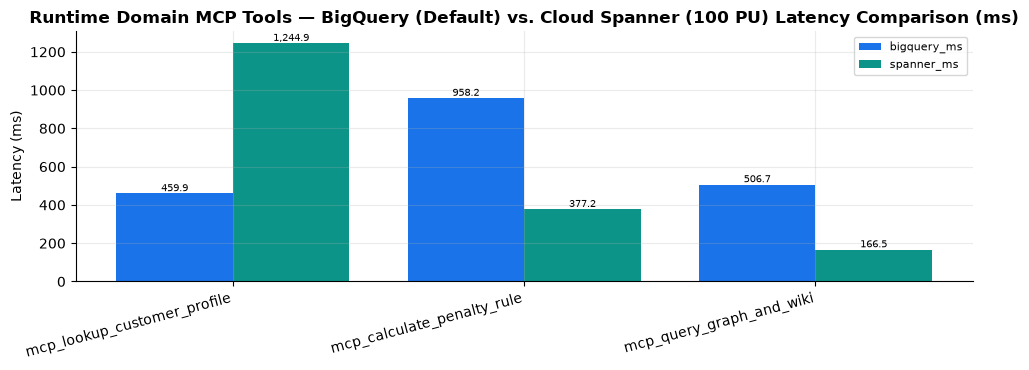

In [5]:
df_mcp_eng = H.compare_mcp_engines(server)
H.show(df_mcp_eng)
H.grouped_bar(df_mcp_eng, "mcp_tool", ["bigquery_ms", "spanner_ms"],
              "Runtime Domain MCP Tools — BigQuery (Default) vs. Cloud Spanner (100 PU) Latency Comparison (ms)",
              fmt="{:,.1f}", ylabel="Latency (ms)")


### 5. [Phase 7: End-to-End 2-Pass Agent Answering] Golden CQs (`GROUNDED`) & Boundary Guardrails (`INSUFFICIENT_PARAMETERS`, `MATCH_NOT_FOUND`)


#### CQ-01 (Subsidy & Net Price)
**Q.** When activating the AlphaPhone 16 Pro 256GB on the 5G Signature 115 plan, what are the public subsidy, retail additional subsidy cap, total subsidy, and net purchase price?

- **Step 1 (Decomposition & Slot Extraction)**: sub-goals - · params `{"storage_gb": 256}`
- **Step 2 (Deterministic MCP Tool Dispatch)**:

| # | MCP Tool | Status | Rows/Paths | BigQuery ms | BigQuery Job ID |
|---:|:---|:---|---:|---:|:---|
| 1 | `mcp_query_graph_and_wiki` | `SUCCESS` | 10 | 603 | `job_Udyk_oRklIB0xoxDUv9amvFMhuh0` |

- **`mcp_query_graph_and_wiki` Executed GQL & Bound Variables** (`params={"storage_gb": 256}`):
```sql
SELECT g.*, ch.section_title, ch.content_sha256 AS anchor, ch.content AS chunk_text
FROM GRAPH_TABLE(`seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
  MATCH (d:DeviceNode)-[hs:HAS_SUBSIDY_POLICY]->(p:PlanNode)<-[ap:APPLIES_TO_PLAN]-(r:DomainRuleNode)
  COLUMNS (hs.policy_id AS policy_id, hs.total_subsidy_krw AS total_subsidy_krw, d.device_name AS device_name, d.factory_price_krw AS factory_price_krw,
           p.plan_name AS plan_name, p.monthly_fee_krw AS monthly_fee_krw,
           r.rule_id AS rule_id, r.rule_name AS rule_name,
           ap.relation_label_ko AS relation_label_ko, ap.source_chunk_id AS source_chunk_id)) g
LEFT JOIN `seanjung-poc.starter_ontology_dw.tb_doc_chunks` ch ON ch.chunk_id = g.source_chunk_id
WHERE TRUE
ORDER BY g.device_name, g.monthly_fee_krw DESC, g.rule_id
```

- **Step 3 (Grounding & Guardrail Verdict)**: `answer_status=GROUNDED` · anchors `[]` · Gemini `gemini-3.8-flash` (2 calls, 5,855 tokens, LLM 21,766 ms / total 22.82 s)

- **Step 4 (Synthesized Grounded Answer)**:

> `: `DOC_CHUNK_005`, `anchor_4fbaf9c5cba8` ("24-Month Contract TCO Comparison Rule")
>
> 4. **Execution Telemetry**:
> - BigQuery Job IDs: `job_Udyk_oRklIB0xoxDUv9amvFMhuh0`
> - BigQuery Elapsed Time

#### CQ-02 (120d Prorated Penalty)
**Q.** If customer CUST_DEMO_001 downgrades to the 37,000 KRW monthly plan (5G Lite 37) on day 120 after activation, what is the prorated difference penalty?

- **Step 1 (Decomposition & Slot Extraction)**: sub-goals - · params `{"target_plan_name": "5G Light (Below Baseline)", "customer_id": "CUST_DEMO_001", "target_monthly_fee_krw": 37000, "elapsed_days": 120, "target_plan_mention": "37,000 KRW monthly plan (5G Lite 37)"}`
- **Step 2 (Deterministic MCP Tool Dispatch)**:

| # | MCP Tool | Status | Rows/Paths | BigQuery ms | BigQuery Job ID |
|---:|:---|:---|---:|---:|:---|
| 1 | `mcp_lookup_customer_profile` | `SUCCESS` | 1 | 508 | `job_byJTcD-KMfG5WvUaQsP1eH8IVNkd` |
| 2 | `mcp_stage4_agent_orchestration` | `SUCCESS` | - | 486 | `job_ZUbE51XTUMsDTh-bf8l5NMyXIwke` |
| 3 | `mcp_calculate_penalty_rule` | `SUCCESS` | 1 | 983 | `job_2GB-x_HUbJScjxbKO1AOkFfxp1DI`, `job_9OUrRbsKmAZJw5LpNjuqdAIf1nDA` |
| 4 | `mcp_query_graph_and_wiki` | `SUCCESS` | 2 | 588 | `job_TsUaku2lASk6uS2Won_KAOGsAMWo` |

- **`mcp_query_graph_and_wiki` Executed GQL & Bound Variables** (`params={"target_plan_name": "5G Light (Below Baseline)", "customer_id": "CUST_DEMO_001", "target_monthly_fee_krw": 37000, "elapsed_days": 120, "target_plan_mention": "37,000 KRW monthly plan (5G Lite 37)"}`):
```sql
SELECT g.*, ch.section_title, ch.content_sha256 AS anchor, ch.content AS chunk_text
FROM GRAPH_TABLE(`seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
  MATCH (c:CustomerContractNode)-[:USES_DEVICE]->(d:DeviceNode), (c)-[:SUBSCRIBES_PLAN]->(p:PlanNode)<-[ap:APPLIES_TO_PLAN]-(r:DomainRuleNode)
  COLUMNS (c.customer_id AS customer_id, c.contract_id AS contract_id, c.welfare_status AS welfare_status, c.elapsed_days AS elapsed_days, d.device_name AS device_name, d.factory_price_krw AS factory_price_krw,
           p.plan_name AS plan_name, p.monthly_fee_krw AS monthly_fee_krw,
           r.rule_id AS rule_id, r.rule_name AS rule_name,
           ap.relation_label_ko AS relation_label_ko, ap.source_chunk_id AS source_chunk_id)) g
LEFT JOIN `seanjung-poc.starter_ontology_dw.tb_doc_chunks` ch ON ch.chunk_id = g.source_chunk_id
WHERE g.customer_id = 'CUST_DEMO_001'
ORDER BY g.device_name, g.monthly_fee_krw DESC, g.rule_id
```

- **Step 3 (Grounding & Guardrail Verdict)**: `answer_status=GROUNDED` · anchors `[]` · Gemini `gemini-3.8-flash` (2 calls, 7,589 tokens, LLM 21,822 ms / total 24.39 s)

- **Step 4 (Synthesized Grounded Answer)**:

> ### Conclusion
> The prorated difference penalty for customer **CUST_DEMO_001** downgrading to the **5G Light (Below Baseline)** plan (37,000 KRW/month) on day 120 is **100,000 KRW**.
>
> ---
>
> ### Grounded Data (BigQuery)
>
> * **Customer ID**: CUST_DEMO_001
> * **Contract ID**: CONTRACT_DEMO_101
> * **Contract Type**: PUBLIC_SUBSIDY
> * **Welfare Status**: NONE
> * **Elapsed Days**: 120
> * **Mandatory Retention Period**: 180 days
> * **Baseline Monthly Fee Threshold**: 45,000 KRW
> * **Current Plan**: 5G Premier Essential (PLAN-5G-85)
>   * Current Monthly Fee: 85,000 KRW
>   * Current Base Subsidy: 450,000 KRW
>   * Additional Subsidy: 67,500 KRW
>   * Total Subsidy Granted: 517,500 KRW
> * **Target Plan**: 5G Light (Below Baseline) (PLAN-5G-37)
>   * Target Monthly Fee: 37,000 KRW
>   * Target Base Subsidy: 150,000 KRW
> * **Penalty Calculation**:
>   $$\text{Penalty} = \text{ROUND}\left((\text{initial\_base\_subsidy} - \text{lower\_tier\_base\_subsidy}) \times \frac{180 - \text{elapsed\_days}}{180}\right)$$
>   $$\text{Penalty} = (450,000 - 150,000) \times \frac{180 - 120}{180} = 300,000 \times \frac{60}{180} = 100,000\text{ KRW}$$
> * **Penalty Status**: PRORATED_PENALTY (100,000 KRW)
>
> ---
>
> ### Applied Rules & Source Chunks
>
> * **RULE_SIX_PLAN_180D**: 180-Day Baseline (45,000 KRW) Mandatory Retention & Prorated Penalty Rule
>   * **Source Chunk ID**: DOC_CHUNK_003 (Anchor: `anchor_47971ec8e4d8`)
>   * **Graph Reference Chunk ID**: DOC_CHUNK_002 (Anchor: `anchor_3003b683cea0`)
>   * **Condition**: `elapsed_days < 180 AND target_plan_monthly_fee < 45000`
>   * **Formula**: `penalty = ROUND((initial_base_subsidy - lower_tier_base_subsidy) * (180 - elapsed_days) / 180)`
> * **RULE_SUBSIDY_CAP**: Public Subsidy & Retail Additional Subsidy Cap (15%) Rule
>   * **Source Chunk ID**: DOC_CHUNK_001 (Anchor: `anchor_a52e1a72869f`)
> * **RULE_TCO_24M**: 24-Month Public Subsidy vs. 25% Selective Contract TCO Comparison Rule
>   * **Source Chunk ID**: DOC_CHUNK_005 (Anchor: `anchor_4fbaf9c5cba8`)
> * **RULE_WELFARE_EXEMPT**: Senior/Welfare Plan Transition & Military Suspension Penalty Exemption Rule
>   * **Source Chunk ID**: DOC_CHUNK_004 (Anchor: `anchor_269d9c42e05c`)
>
> ---
>
> ### Execution Telemetry
> * **BigQuery Job IDs**:
>   * `job_byJTcD-KMfG5WvUaQsP1eH8IVNkd` (mcp_lookup_customer_profile)
>   * `job_ZUbE51XTUMsDTh-bf8l5NMyXIwke` (mcp_stage4_agent_orchestration)
>   * `job_2GB-x_HUbJScjxbKO1AOkFfxp1DI` (mcp_calculate_penalty_rule)
>   * `job_9OUrRbsKmAZJw5LpNjuqdAIf1nDA` (mcp_calculate_penalty_rule)
>   * `job_TsUaku2lASk6uS2Won_KAOGsAMWo` (mcp_query_graph_and_wiki)

#### CQ-03 (Welfare Exemption)
**Q.** Is customer CUST_DEMO_002 (registered under National Merit Welfare) exempt from penalty charges when downgrading to a lower plan on day 95?

- **Step 1 (Decomposition & Slot Extraction)**: sub-goals - · params `{"customer_id": "CUST_DEMO_002", "elapsed_days": 95, "target_plan_mention": "a lower plan"}`
- **Step 2 (Deterministic MCP Tool Dispatch)**:

| # | MCP Tool | Status | Rows/Paths | BigQuery ms | BigQuery Job ID |
|---:|:---|:---|---:|---:|:---|
| 1 | `mcp_lookup_customer_profile` | `SUCCESS` | 1 | 472 | `job_sXxhTnUMnRX0qb6DQj70i_tFvaSE` |
| 2 | `mcp_query_graph_and_wiki` | `SUCCESS` | 2 | 503 | `job_uJfNGbbZ-NGRExlgL665kc4LFsCJ` |
| 3 | `mcp_calculate_penalty_rule` | `SUCCESS` | 1 | 834 | `job_e_BgRjrobB51-6HRciIKNe7lVx74`, `job_A9SICIN4naNER6pjgHHALBtoPoWM` |

- **`mcp_query_graph_and_wiki` Executed GQL & Bound Variables** (`params={"customer_id": "CUST_DEMO_002", "elapsed_days": 95, "target_plan_mention": "a lower plan"}`):
```sql
SELECT g.*, ch.section_title, ch.content_sha256 AS anchor, ch.content AS chunk_text
FROM GRAPH_TABLE(`seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
  MATCH (c:CustomerContractNode)-[:USES_DEVICE]->(d:DeviceNode), (c)-[:SUBSCRIBES_PLAN]->(p:PlanNode)<-[ap:APPLIES_TO_PLAN]-(r:DomainRuleNode)
  COLUMNS (c.customer_id AS customer_id, c.contract_id AS contract_id, c.welfare_status AS welfare_status, c.elapsed_days AS elapsed_days, d.device_name AS device_name, d.factory_price_krw AS factory_price_krw,
           p.plan_name AS plan_name, p.monthly_fee_krw AS monthly_fee_krw,
           r.rule_id AS rule_id, r.rule_name AS rule_name,
           ap.relation_label_ko AS relation_label_ko, ap.source_chunk_id AS source_chunk_id)) g
LEFT JOIN `seanjung-poc.starter_ontology_dw.tb_doc_chunks` ch ON ch.chunk_id = g.source_chunk_id
WHERE g.customer_id = 'CUST_DEMO_002'
ORDER BY g.device_name, g.monthly_fee_krw DESC, g.rule_id
```

- **Step 3 (Grounding & Guardrail Verdict)**: `answer_status=GROUNDED` · anchors `[]` · Gemini `gemini-3.8-flash` (2 calls, 6,552 tokens, LLM 13,911 ms / total 15.72 s)

- **Step 4 (Synthesized Grounded Answer)**:

> ### **Conclusion**
> **No, customer `CUST_DEMO_002` is not exempt from penalty charges.**
>
> According to BigQuery contract records, customer `CUST_DEMO_002` has a registered `welfare_status` of **`NONE`** (not National Merit Welfare or Senior Welfare). Under rule `RULE_WELFARE_EXEMPT`, penalty exemptions strictly require `welfare_status IN ('SENIOR_EXEMPT', 'MILITARY_PAUSE_ELIGIBLE')`. 
>
> Because the customer is on a `PUBLIC_SUBSIDY` contract with a mandatory retention period of 180 days and downgrading at day 95 (`elapsed_days = 95 < 180`), downgrading to a plan below the baseline threshold of 45,000 KRW/month triggers a prorated clawback penalty under `RULE_SIX_PLAN_180D`.
>
> ---
>
> ### **Grounded Data (BigQuery)**
>
> - **Customer ID**: `CUST_DEMO_002`
> - **Contract ID**: `CONTRACT_DEMO_102`
> - **Customer Segment**: `General_Standard`
> - **Age Group**: `30s-40s`
> - **Welfare Status**: `NONE`
> - **Contract Type**: `PUBLIC_SUBSIDY`
> - **Commitment Months**: 24 months
> - **Subscribed Plan**: `5G Premier Super` (`PLAN-5G-130`)
> - **Plan Monthly Fee**: 130,000 KRW
> - **Device**: `Galaxy S26 Ultra 256GB` (`DEV-S26U-256`)
> - **Factory Price**: 1,698,400 KRW
> - **Base Subsidy**: 500,000 KRW
> - **Additional Subsidy Cap**: 75,000 KRW
> - **Total Granted Subsidy**: 575,000 KRW
> - **Mandatory Retention Period**: 180 days
> - **Evaluation Day**: 95 days
> - **Baseline Plan Fee Threshold**: 45,000 KRW
>
> ---
>
> ### **Applied Rules & Source Chunks**
>
> 1. **`RULE_WELFARE_EXEMPT`**
>    - **Rule Name**: Senior/Welfare Plan Transition & Military Suspension Penalty Exemption Rule
>    - **Condition**: `welfare_status IN ('SENIOR_EXEMPT', 'MILITARY_PAUSE_ELIGIBLE')`
>    - **Formula**: `penalty = 0 (SENIOR_EXEMPT) OR pause_commitment_counter (MILITARY_PAUSE_ELIGIBLE)`
>    - **Source Chunk ID**: `DOC_CHUNK_004`
>    - **Anchor**: `anchor_269d9c42e05c`
>    - **Application**: The customer's registered `welfare_status` is `NONE`, disqualifying them from exemption.
>
> 2. **`RULE_SIX_PLAN_180D`**
>    - **Rule Name**: 180-Day Baseline (45,000 KRW) Mandatory Retention & Prorated Penalty Rule
>    - **Condition**: `elapsed_days < 180 AND target_plan_monthly_fee < 45000`
>    - **Formula**: `penalty = ROUND((initial_base_subsidy - lower_tier_base_subsidy) * (180 - elapsed_days) / 180)`
>    - **Source Chunk IDs**: `DOC_CHUNK_002` (Anchor: `anchor_3003b683cea0`), `DOC_CHUNK_003` (Anchor: `anchor_47971ec8e4d8`)
>    - **Application**: At day 95 (`elapsed_days = 95`), a downgrade to any plan below 45,000 KRW/month incurs a prorated clawback on the base subsidy difference across the remaining 85 days (`(180 - 95) / 180`).
>
> ---
>
> ### **Execution Telemetry**
>
> - **Customer Profile Lookup Job ID**: `job_sXxhTnUMnRX0qb6DQj70i_tFvaSE`
> - **Ontology Graph & Knowledge Base Job ID**: `job_uJfNGbbZ-NGRExlgL665kc4LFsCJ`
> - **Penalty Calculation Job IDs**: `job_e_BgRjrobB51-6HRciIKNe7lVx74`, `job_A9SICIN4naNER6pjgHHALBtoPoWM`

#### BC-PARAM (Missing Customer/Device)
**Q.** I am a newly activated subscriber—what is the penalty if I downgrade to the 5G Lite 37 plan right now?

- **Step 1 (Decomposition & Slot Extraction)**: sub-goals - · params `{}`
- **Step 2 (Deterministic MCP Tool Dispatch)**:

| # | MCP Tool | Status | Rows/Paths | BigQuery ms | BigQuery Job ID |
|---:|:---|:---|---:|---:|:---|
| 1 | `mcp_query_graph_and_wiki` | `SUCCESS` | 10 | 563 | `job_jPOmepurjNfUhF76QprV1ponLwf_` |

- **`mcp_query_graph_and_wiki` Executed GQL & Bound Variables** (`params={}`):
```sql
SELECT g.*, ch.section_title, ch.content_sha256 AS anchor, ch.content AS chunk_text
FROM GRAPH_TABLE(`seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
  MATCH (d:DeviceNode)-[hs:HAS_SUBSIDY_POLICY]->(p:PlanNode)<-[ap:APPLIES_TO_PLAN]-(r:DomainRuleNode)
  COLUMNS (hs.policy_id AS policy_id, hs.total_subsidy_krw AS total_subsidy_krw, d.device_name AS device_name, d.factory_price_krw AS factory_price_krw,
           p.plan_name AS plan_name, p.monthly_fee_krw AS monthly_fee_krw,
           r.rule_id AS rule_id, r.rule_name AS rule_name,
           ap.relation_label_ko AS relation_label_ko, ap.source_chunk_id AS source_chunk_id)) g
LEFT JOIN `seanjung-poc.starter_ontology_dw.tb_doc_chunks` ch ON ch.chunk_id = g.source_chunk_id
WHERE TRUE
ORDER BY g.device_name, g.monthly_fee_krw DESC, g.rule_id
```

- **Step 3 (Grounding & Guardrail Verdict)**: `answer_status=GROUNDED` · anchors `[]` · Gemini `gemini-3.8-flash` (2 calls, 5,816 tokens, LLM 20,857 ms / total 21.42 s)

- **Step 4 (Synthesized Grounded Answer)**:

> ### Conclusion
>
> A subsidy difference penalty will be levied if you downgrade to the **5G Light (Below Baseline)** plan (37,000 KRW/month) right now. Under carrier regulations, subscribers receiving a public device subsidy must maintain an initial plan at or above the designated 5G Baseline Plan Threshold of **45,000 KRW/month** for

#### BC-NOTFOUND (Unknown Entity)
**Q.** Please calculate the penalty when customer CUST_NOT_EXIST_999 changes plans with a QuantumFold 99 device.

- **Step 1 (Decomposition & Slot Extraction)**: sub-goals - · params `{"device_mention": "QuantumFold 99"}`
- **Step 2 (Deterministic MCP Tool Dispatch)**:

| # | MCP Tool | Status | Rows/Paths | BigQuery ms | BigQuery Job ID |
|---:|:---|:---|---:|---:|:---|
| 1 | `mcp_lookup_customer_profile` | `SUCCESS` | 7 | 443 | `job_KdD-RrCWhhQ_OwhqZ4J_5Dx4n4W4` |
| 2 | `mcp_calculate_penalty_rule` | `INSUFFICIENT_PARAMETERS` | - | 431 | `job_T1ZtqnHUG_sx1hQtdgpbZ2HTpkq5` |
| 3 | `mcp_query_graph_and_wiki` | `SUCCESS` | 10 | 547 | `job_0zxMMGjlV017puLjT6cK1MvGAO0z` |

- **`mcp_query_graph_and_wiki` Executed GQL & Bound Variables** (`params={"device_mention": "QuantumFold 99"}`):
```sql
SELECT g.*, ch.section_title, ch.content_sha256 AS anchor, ch.content AS chunk_text
FROM GRAPH_TABLE(`seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
  MATCH (d:DeviceNode)-[hs:HAS_SUBSIDY_POLICY]->(p:PlanNode)<-[ap:APPLIES_TO_PLAN]-(r:DomainRuleNode)
  COLUMNS (hs.policy_id AS policy_id, hs.total_subsidy_krw AS total_subsidy_krw, d.device_name AS device_name, d.factory_price_krw AS factory_price_krw,
           p.plan_name AS plan_name, p.monthly_fee_krw AS monthly_fee_krw,
           r.rule_id AS rule_id, r.rule_name AS rule_name,
           ap.relation_label_ko AS relation_label_ko, ap.source_chunk_id AS source_chunk_id)) g
LEFT JOIN `seanjung-poc.starter_ontology_dw.tb_doc_chunks` ch ON ch.chunk_id = g.source_chunk_id
WHERE TRUE
ORDER BY g.device_name, g.monthly_fee_krw DESC, g.rule_id
```

- **Step 3 (Grounding & Guardrail Verdict)**: `answer_status=INSUFFICIENT_PARAMETERS` · anchors `[]` · Gemini `gemini-3.8-flash` (2 calls, 9,051 tokens, LLM 17,901 ms / total 19.33 s)

- **Step 4 (Synthesized Grounded Answer)**:

> ### Conclusion
> The penalty calculation cannot be completed because the calculation engine returned an `INSUFFICIENT_PARAMETERS` status. Customer `CUST_NOT_EXIST_999` and device `QuantumFold 99` do not match any active subscription profile in BigQuery (`seanjung-poc.starter_ontology_dw`). 
>
> To compute the exact penalty, the following required parameters (`missing_slots

,id,answer_status,tools,bq_jobs,tokens,llm_ms,bq_ms,total_s
0,CQ-01,GROUNDED,query_graph_and_wiki,2,5855,21766,603,22.82
1,CQ-02,GROUNDED,lookup_customer_profile > stage4_agent_orchestration > calculate_penalty_rule > query_...,6,7589,21822,2565,24.39
2,CQ-03,GROUNDED,lookup_customer_profile > query_graph_and_wiki > calculate_penalty_rule,5,6552,13911,1810,15.72
3,BC-PARAM,GROUNDED,query_graph_and_wiki,2,5816,20857,563,21.42
4,BC-NOTFOUND,INSUFFICIENT_PARAMETERS,lookup_customer_profile > calculate_penalty_rule > query_graph_and_wiki,4,9051,17901,1421,19.33


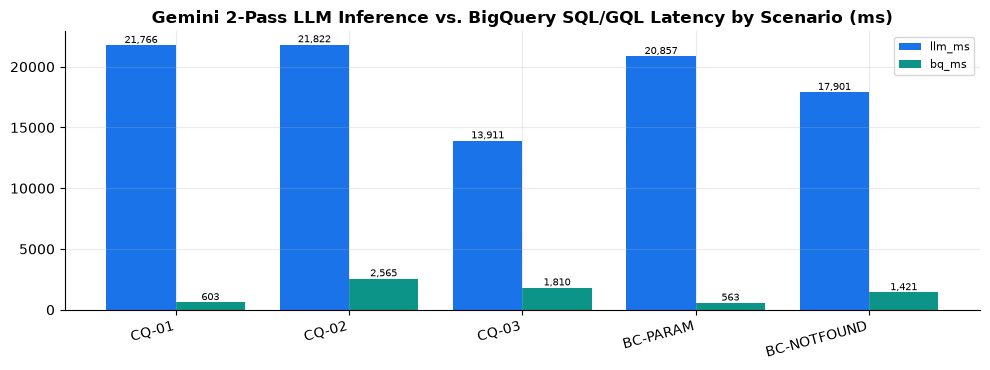

In [6]:
prompts = [
    ("CQ-01 (Subsidy & Net Price)", "When activating the AlphaPhone 16 Pro 256GB on the 5G Signature 115 plan, what are the public subsidy, retail additional subsidy cap, total subsidy, and net purchase price?"),
    ("CQ-02 (120d Prorated Penalty)", "If customer CUST_DEMO_001 downgrades to the 37,000 KRW monthly plan (5G Lite 37) on day 120 after activation, what is the prorated difference penalty?"),
    ("CQ-03 (Welfare Exemption)", "Is customer CUST_DEMO_002 (registered under National Merit Welfare) exempt from penalty charges when downgrading to a lower plan on day 95?"),
    ("BC-PARAM (Missing Customer/Device)", "I am a newly activated subscriber—what is the penalty if I downgrade to the 5G Lite 37 plan right now?"),
    ("BC-NOTFOUND (Unknown Entity)", "Please calculate the penalty when customer CUST_NOT_EXIST_999 changes plans with a QuantumFold 99 device."),
]
runs = []
for qid, q in prompts:
    res = agent.execute_cycle(q)
    H.show_agent(res, title=qid)
    runs.append(H.agent_row(res, qid.split()[0]))
df_runs = pd.DataFrame(runs)
H.show(df_runs)
H.grouped_bar(df_runs, "id", ["llm_ms", "bq_ms"],
              "Gemini 2-Pass LLM Inference vs. BigQuery SQL/GQL Latency by Scenario (ms)")


### Q&A
- **Q.** How does the AI FDE Agent prevent penalty calculation errors and hallucinated entities, and how does it switch between `bigquery` and `spanner` engines?
  - **A.** `resolve_params()` validates extracted slots against the live catalog (`get_live_catalog()`), delegates all SQL/GQL execution to the 8 MCP tools across `engine='bigquery'` (default) or `engine='spanner'`, and enforces explicit `INSUFFICIENT_PARAMETERS` and `MATCH_NOT_FOUND` guardrail states.

### Data Analysis Key Findings
- Across elapsed days 30..200 for `CUST_DEMO_001`, the prorated penalty decreases linearly from `250,000 KRW` (day 30) to `100,000 KRW` (day 120) and `1,667 KRW` (day 179), dropping to `0 KRW` (`EXEMPT_RETENTION_COMPLETED`) at day 180.
- Executing all 3 runtime domain MCP tools across `engine='bigquery'` (default) and `engine='spanner'` (`100 PU`) confirmed identical row counts (`result_parity=True`) and SHA-256 anchor grounding.
- All Golden CQs (`CQ-01`–`CQ-03`) returned `GROUNDED` responses citing exact SQL-computed figures (`575,000 KRW`, `100,000 KRW`, `0 KRW`), while `BC-PARAM` and `BC-NOTFOUND` triggered their guardrail states with 0 hallucinated figures.

### Insights or Next Steps
- Proceed to the final `Stage 5 (Verify & Evaluate)` notebook to inspect the 4-Tier end-to-end data lineage graph, Golden CQ re-verification, and the 50-trial boundary benchmark release gate.

---
> **Next Navigation**: [⬅️ Stage 3 · Build Property Graph](./stage3_property_graph_bigquery_spanner_en.ipynb) ｜ [🏠 0. Overview Home](./stage0_overview_walkthrough_en.ipynb) ｜ [➡️ Stage 5 · Verify & Evaluate](./stage5_lineage_and_evaluation_en.ipynb) ｜ [🌐 Korean Version](../ko/stage4_agent_and_mcp_execution_ko.ipynb) ｜ [📖 Methodology Doc](../../methodology/en/04_stage4_agent_and_mcp_en.md)
